# Практика 18. Множинна лінійна регресія

**Студент:** Huz_Yurii  
**Група:** IT-41  
**Варіант:** N=3, Одеса

Мета: побудувати множинну лінійну регресію для витрат на опалення, інтерпретувати коефіцієнти за інших рівних умов, перевірити мультиколінеарність, порівняти моделі та діагностувати залишки.

## Побудова даних варіанта

Використано середньорічну температуру 11.5°C, сезонну амплітуду 13°C і базову вологість 73% для Одеси. Як у рецепті, правила опалювальних днів застосовуються до неокругленої температури, а значення температури, вологості й витрат округлюються до одного десяткового знака перед внесенням у таблицю.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(42)
city = "Одеса"
mean_temp = 11.5
amplitude = 13
hum_base = 73

rows = []
for month in range(1, 13):
    temp = mean_temp + amplitude * np.cos((month - 7) / 12 * 2 * np.pi) + np.random.normal(0, 1.0)
    humidity = hum_base + np.random.normal(0, 5.0)
    if temp < 8:
        opal_days = 30
    elif temp < 12:
        opal_days = 15
    else:
        opal_days = 0

    cost = (
        200
        - 9.0 * temp
        + 0.6 * humidity
        + 2.5 * opal_days
        + np.random.normal(0, 15)
    )
    rows.append({
        "місто": city,
        "місяць": month,
        "температура": round(temp, 1),
        "вологість": round(humidity, 1),
        "опалювальні_дні": opal_days,
        "витрати_на_опалення": round(cost, 1),
    })

heating = pd.DataFrame(rows)
display(heating)

,місто,місяць,температура,вологість,опалювальні_дні,витрати_на_опалення
0,Одеса,1,-1.0,72.3,30,337.1
1,Одеса,2,1.8,71.8,30,298.7
2,Одеса,3,6.6,76.8,30,254.8
3,Одеса,4,12.0,70.7,0,127.0
4,Одеса,5,18.2,63.4,0,48.0
5,Одеса,6,22.2,67.9,0,45.7
6,Одеса,7,23.6,65.9,0,49.2
7,Одеса,8,22.5,73.3,0,19.8
8,Одеса,9,17.5,73.6,0,69.8
9,Одеса,10,11.9,70.0,15,168.2


## Завдання 1. Модель із двома предикторами

Побудуємо OLS-модель витрат за температурою та вологістю. Константа додається явно функцією `sm.add_constant()`.

In [2]:
y = heating["витрати_на_опалення"]
X_two = sm.add_constant(heating[["температура", "вологість"]])
model_two = sm.OLS(y, X_two).fit()
print(model_two.summary())
print(f"R² = {model_two.rsquared:.6f}")
print(f"Adjusted R² = {model_two.rsquared_adj:.6f}")

                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.966
Model:                             OLS   Adj. R-squared:                  0.958
Method:                  Least Squares   F-statistic:                     126.2
Date:                 Tue, 13 Oct 2026   Prob (F-statistic):           2.61e-07
Time:                         22:10:49   Log-Likelihood:                -53.943
No. Observations:                   12   AIC:                             113.9
Df Residuals:                        9   BIC:                             115.3
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         213.8133    139.184      1

## Завдання 2. Інтерпретація коефіцієнтів

Інтерпретація коефіцієнта множинної регресії утримує інший предиктор сталим. У результаті цього варіанта за незмінної вологості підвищення температури на 1°C пов'язане зі зменшенням очікуваних витрат приблизно на **12.505 умовних одиниць**; за незмінної температури підвищення вологості на 1 процентний пункт відповідає зміні очікуваних витрат приблизно на **1.369 умовних одиниць**. Значущість оцінюємо за p-value окремого t-тесту при α=0.05.

In [3]:
alpha = 0.05
for name in ["температура", "вологість"]:
    coef = model_two.params[name]
    p_value = model_two.pvalues[name]
    significance = "є підстави вважати предиктор статистично значущим" if p_value < alpha else "немає підстав вважати предиктор статистично значущим"
    print(f"{name}: коефіцієнт={coef:.3f}, P>|t|={p_value:.6g}; {significance} за інших рівних умов при α={alpha}.")

температура: коефіцієнт=-12.505, P>|t|=6.4035e-07; є підстави вважати предиктор статистично значущим за інших рівних умов при α=0.05.
вологість: коефіцієнт=1.369, P>|t|=0.472425; немає підстав вважати предиктор статистично значущим за інших рівних умов при α=0.05.


## Завдання 3. Мультиколінеарність у двопредикторній моделі

VIF показує, наскільки дисперсія оцінки коефіцієнта зростає через лінійну залежність цього предиктора від інших. Константу не інтерпретуємо як предиктор.

In [4]:
vif_two = pd.DataFrame({
    "предиктор": [col for col in X_two.columns if col != "const"],
    "VIF": [variance_inflation_factor(X_two.values, i) for i, col in enumerate(X_two.columns) if col != "const"],
})
display(vif_two.round(3))

,предиктор,VIF
0,температура,1.559
1,вологість,1.559


VIF температури та вологості становлять приблизно **1.559** для кожного — нижче за практичний поріг 5, отже серед цих двох предикторів немає ознаки проблемної мультиколінеарності. Це узгоджується з генератором: температура формується сезонною хвилею, тоді як вологість генерується окремо як `hum_base + normal(0, 5.0)` і прямо від температури не залежить.

## Завдання 4. Додавання третього предиктора

Додаємо кількість опалювальних днів і порівнюємо звичайний та скоригований коефіцієнти детермінації. Також обчислимо VIF трипредикторної моделі, щоб оцінити спільне сезонне походження температури й опалювальних днів.

In [5]:
X_three = sm.add_constant(heating[["температура", "вологість", "опалювальні_дні"]])
model_three = sm.OLS(y, X_three).fit()
print(model_three.summary())

model_comparison = pd.DataFrame({
    "модель": ["Температура + вологість", "Температура + вологість + опалювальні дні"],
    "R²": [model_two.rsquared, model_three.rsquared],
    "Adjusted R²": [model_two.rsquared_adj, model_three.rsquared_adj],
})
display(model_comparison.round(4))

vif_three = pd.DataFrame({
    "предиктор": [col for col in X_three.columns if col != "const"],
    "VIF": [variance_inflation_factor(X_three.values, i) for i, col in enumerate(X_three.columns) if col != "const"],
})
display(vif_three.round(3))

                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.989
Model:                             OLS   Adj. R-squared:                  0.985
Method:                  Least Squares   F-statistic:                     246.5
Date:                 Tue, 13 Oct 2026   Prob (F-statistic):           3.22e-08
Time:                         22:10:57   Log-Likelihood:                -46.933
No. Observations:                   12   AIC:                             101.9
Df Residuals:                        8   BIC:                             103.8
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             239.8118     8

,модель,R²,Adjusted R²
0,Температура + вологість,0.9656,0.9579
1,Температура + вологість + опалювальні дні,0.9893,0.9853


,предиктор,VIF
0,температура,6.742
1,вологість,1.796
2,опалювальні_дні,7.747


Після додавання опалювальних днів R² зростає з **0.9656** до **0.9893**, а adjusted R² — з **0.9579** до **0.9853**. Отже, покращення достатнє, щоб компенсувати штраф за додатковий предиктор у цьому наборі. Водночас VIF температури становить близько **6.742**, а опалювальних днів — **7.747**: це вище порога уваги 5, хоча нижче порога 10. Така колінеарність очікувана: обидва стовпці відображають сезонність, причому холодніша температура зазвичай відповідає більшій кількості опалювальних днів. Тому покращення загальної відповідності не означає, що їхні окремі коефіцієнти оцінені незалежно з високою точністю.

## Завдання 5. Діагностика залишків двопредикторної моделі

Перевіримо залишки проти fitted values на можливу лійкоподібну форму та побудуємо QQ-графік. Тест Шапіро—Вілка доповнює, але не замінює графічну перевірку.

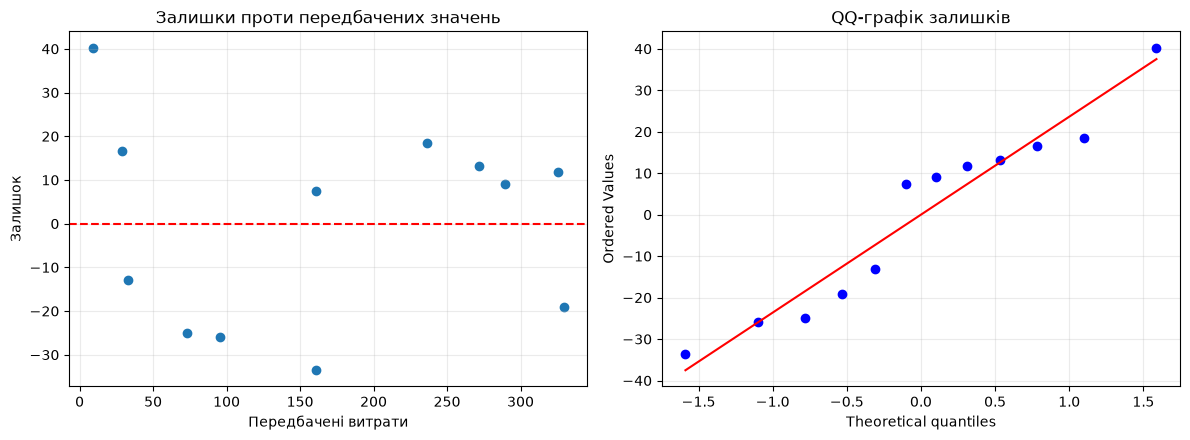

Shapiro-Wilk: W=0.9285, p-value=0.364611
Не відхиляємо H₀ про нормальність залишків при α=0.05.


In [6]:
fitted = model_two.fittedvalues
residuals = model_two.resid

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.scatter(fitted, residuals)
ax1.axhline(0, color="red", linestyle="--")
ax1.set_xlabel("Передбачені витрати")
ax1.set_ylabel("Залишок")
ax1.set_title("Залишки проти передбачених значень")
ax1.grid(alpha=0.25)

stats.probplot(residuals, dist="norm", plot=ax2)
ax2.set_title("QQ-графік залишків")
ax2.grid(alpha=0.25)
plt.tight_layout()
plt.show()

shapiro_result = stats.shapiro(residuals)
print(f"Shapiro-Wilk: W={shapiro_result.statistic:.4f}, p-value={shapiro_result.pvalue:.6f}")
print("Не відхиляємо H₀ про нормальність залишків при α=0.05." if shapiro_result.pvalue >= alpha else "Відхиляємо H₀ про нормальність залишків при α=0.05.")

Для цього seed тест Шапіро—Вілка дає **p≈0.365**, що більше за 0.05: на рівні значущості 5% немає підстав відхиляти нульову гіпотезу про нормальність залишків. Це не доводить нормальності, особливо за лише 12 місяців. На графіку залишків зверніть увагу на розкид: точки переважно лежать по обидва боки нуля, проте розкид не виглядає цілком рівномірним по діапазону fitted — для найнижчих передбачених значень є значне додатне відхилення, а середні fitted мають і від'ємні відхилення до приблизно −34, і додатні до приблизно +17. Тому переконливої чистої лійки немає, але вибірка мала, а окремі відхилення є; остаточну оцінку слід робити за самим графіком, а не лише за тестом.

## Завдання 6. Порівняння з простою регресією

Оцінимо на тих самих 12 рядках модель лише з температурою та порівняємо її R² зі скоригованим R² двопредикторної моделі.

In [7]:
X_simple = sm.add_constant(heating[["температура"]])
model_simple = sm.OLS(y, X_simple).fit()

print(f"Проста модель (лише температура): R² = {model_simple.rsquared:.6f}")
print(f"Множинна модель (температура + вологість): adjusted R² = {model_two.rsquared_adj:.6f}")
print(f"Різниця adjusted R² множинної моделі мінус R² простої = {model_two.rsquared_adj - model_simple.rsquared:.6f}")

Проста модель (лише температура): R² = 0.963421
Множинна модель (температура + вологість): adjusted R² = 0.957922
Різниця adjusted R² множинної моделі мінус R² простої = -0.005499


У цьому наборі проста модель має R² близько **0.9634**, а скоригований R² моделі з температурою та вологістю — **0.9579**. Отже, після штрафу за додатковий предиктор множинна модель не перевершує просту за цим порівнянням; вологість дає лише невелике додаткове пояснення, яке не компенсує штраф у adjusted R². Звичайний R² при додаванні предиктора не зменшується, бо МНК може щонайменше відтворити попередню модель, надавши новому коефіцієнту нульове значення; adjusted R² штрафує за використання додаткового параметра.

## Контрольні питання

1. **Навіщо `sm.add_constant()`?** Вона додає стовпець одиниць, щоб OLS оцінила вільний перетин разом із нахилами. Без нього statsmodels за замовчуванням оцінює модель без константи, змушуючи регресійну площину проходити через нуль; нахили та якість відповідності можуть істотно змінитися.
2. **Множинний коефіцієнт і простий коефіцієнт.** У множинній регресії коефіцієнт описує зміну прогнозу при зміні відповідного предиктора за фіксованих інших включених змінних. У простій регресії він не контролює інших факторів і може включати їхній спільний зв'язок із предиктором.
3. **R² і додавання предиктора.** Мінімізація залишкової суми квадратів у більшій моделі має всі можливості меншої моделі плюс додатковий коефіцієнт, який можна прирівняти до нуля. Тому R² не падає навіть від непотрібного предиктора. Для порівняння моделей з різною кількістю параметрів варто дивитися на adjusted R² та діагностику, а не лише на звичайний R².
4. **Значення VIF.** VIF близький до 1 означає, що предиктор майже не пояснюється лінійною комбінацією інших. VIF вище 10 вказує на сильну мультиколінеарність і нестабільні/неточні окремі коефіцієнти. На практиці перевіряють, чи дублюють змінні один одного, обґрунтовано прибирають або об'єднують предиктори, збирають більше даних чи використовують методи регуляризації; рішення не слід приймати лише за порогом VIF.

## Підсумок

Для Одеси побудовано OLS-моделі з двома та трьома предикторами, витлумачено коефіцієнти та p-value, виміряно VIF, порівняно R² і adjusted R², перевірено залишки графічно й тестом Шапіро—Вілка та зіставлено двопредикторну модель із простою регресією температури.